## Working directory and import libraries

In [1]:
%load_ext autoreload
%autoreload 2

import os
import sys
import json
import cv2
import torch
import ultralytics
from pathlib import Path

PROJECT_ROOT = "/home/user/NeuroVision-AI-2"

os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))
os.environ["PROJECT_ROOT"] = str(PROJECT_ROOT)
print("Working directory:", os.getcwd())

# import cfgs
from src.config import cfg

#  Quick check
print("python      :", sys.version.split()[0])
print("torch       :", torch.__version__, "| CUDA:", torch.cuda.is_available())
print("ultralytics :", ultralytics.__version__)
print("opencv      :", cv2.__version__)

print("Raw data :", cfg.RAW_DIR)
print("Classes  :", cfg.CLASS_NAMES)
print("Split    : train %.0f%% / val %.0f%% / test %.0f%%" % (
    (1 - cfg.VAL_RATIO - cfg.TEST_RATIO) * 100, cfg.VAL_RATIO * 100, cfg.TEST_RATIO * 100))
print("Seed     :", cfg.SEED)

Working directory: /home/user/NeuroVision-AI-2
python      : 3.10.22
torch       : 2.14.1+cu130 | CUDA: True
ultralytics : 8.4.192
opencv      : 5.0.0
Raw data : /home/user/NeuroVision-AI-2/data/raw
Classes  : ('Glioma', 'Meningioma', 'No Tumor', 'Pituitary')
Split    : train 70% / val 15% / test 15%
Seed     : 42


## download data

In [2]:
from src.dataset import download_dataset

download_dataset()

Dataset already exists, skipping download: /home/user/NeuroVision-AI-2/data/raw


PosixPath('/home/user/NeuroVision-AI-2/data/raw')

## Organizing images/labels into train, valid, test

In [3]:
from src.dataset import collect_pairs

pairs, orphans = collect_pairs()
print("Pairs per class:", {c: len(v) for c, v in pairs.items()})
print("Total pairs    :", sum(len(v) for v in pairs.values()))
print("Orphan images  :", len(orphans))

Pairs per class: {'Glioma': 1289, 'Meningioma': 1589, 'No Tumor': 809, 'Pituitary': 1560}
Total pairs    : 5247
Orphan images  : 2


## Collect image/label pairs and count orphans

In [4]:
from src.dataset import collect_pairs

pairs, orphans = collect_pairs()
print("Pairs per class:", {c: len(v) for c, v in pairs.items()})
print("Total pairs    :", sum(len(v) for v in pairs.values()))
print("Orphan images  :", len(orphans))

Pairs per class: {'Glioma': 1289, 'Meningioma': 1589, 'No Tumor': 809, 'Pituitary': 1560}
Total pairs    : 5247
Orphan images  : 2


## Read a YOLO annotation and convert it to pixels

label: /home/user/NeuroVision-AI-2/data/raw/Train/Glioma/labels/Te-glTr_0000.txt
image: /home/user/NeuroVision-AI-2/data/raw/Train/Glioma/images/Te-glTr_0000.jpg

raw text:
 0 0.555664 0.653320 0.146484 0.193359

parsed  : [(0, 0.555664, 0.65332, 0.146484, 0.193359)]
errors  : none

image size: 512x512
class 0 (Glioma)
  YOLO   : xc=0.5557 yc=0.6533 w=0.1465 h=0.1934
  pixels : x1=247 y1=284 x2=321 y2=383  (74x99 px)


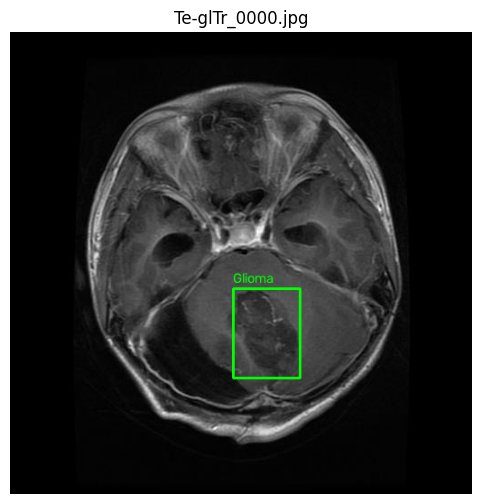

In [5]:
# One annotation, normalized then in pixels
from src.annotations import show_annotation

image_path, label_path = next((i, l) for items in pairs.values() for i, l in items
                              if l.read_text().strip())
show_annotation(image_path, label_path, class_names=cfg.CLASS_NAMES)

## Show 9 images with boxes and class names

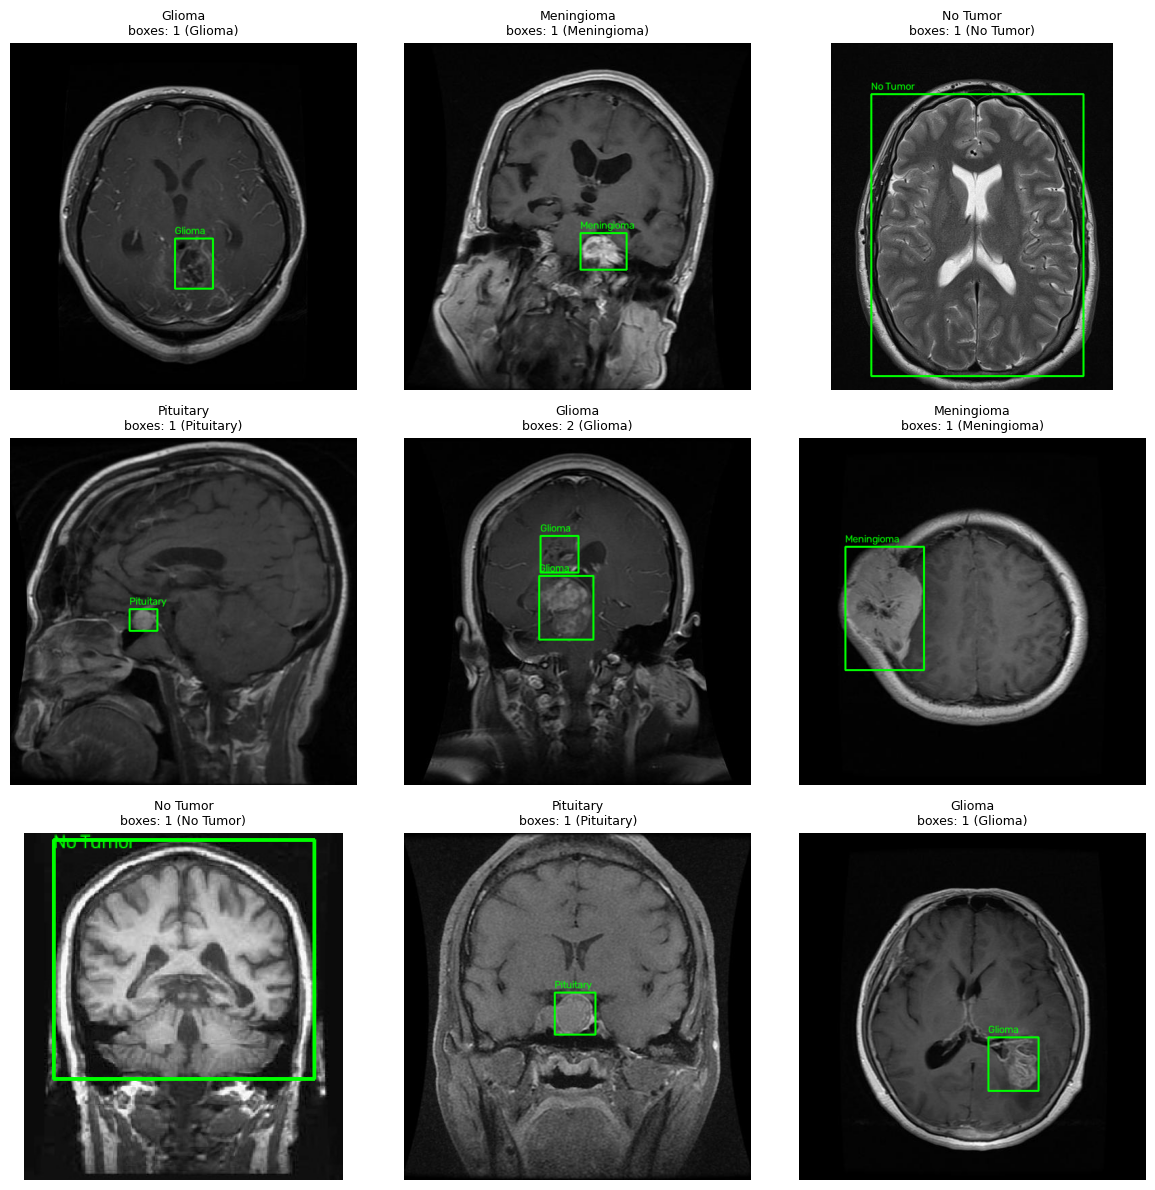

In [6]:
from src.visualization import show_samples_grid

show_samples_grid(pairs, n=9, seed=cfg.SEED, class_names=cfg.CLASS_NAMES)

## Class distribution

,class,images,boxes,empty_labels
0,Glioma,1289,1667,1
1,Meningioma,1589,1731,0
2,No Tumor,809,809,0
3,Pituitary,1560,1664,0


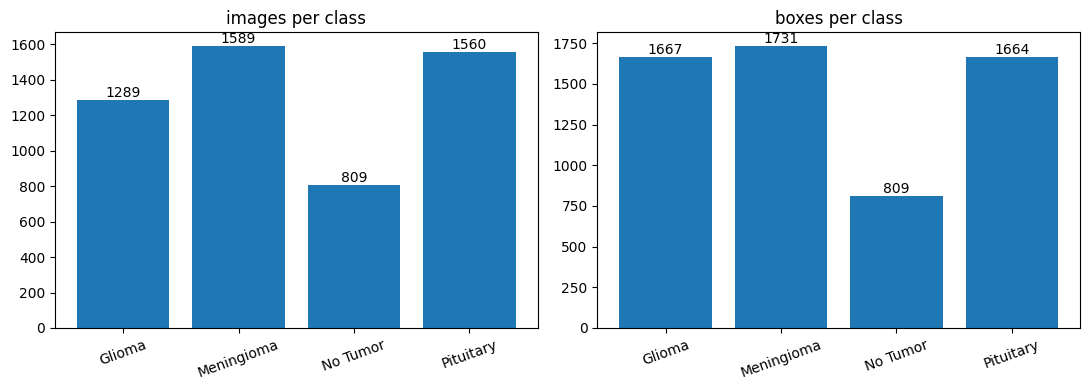

Imbalance ratio (largest / smallest class): 1.96


In [7]:
# Cell 7: Distribution
from src.dataset import class_distribution
from src.visualization import plot_class_distribution

dist = class_distribution(pairs)   # DataFrame: class, images, boxes
display(dist)
plot_class_distribution(dist)
print("Imbalance ratio (largest / smallest class): %.2f" % (dist.images.max() / dist.images.min()))

## Cleaning and validation audit

In [8]:
from src.dataset import audit_dataset

audit = audit_dataset(pairs)
print(json.dumps({k: len(v) for k, v in audit.items()}, indent=2))

Glioma:   0%|          | 0/1289 [00:00<?, ?it/s]

Meningioma:   0%|          | 0/1589 [00:00<?, ?it/s]

No Tumor:   0%|          | 0/809 [00:00<?, ?it/s]

Pituitary:   0%|          | 0/1560 [00:00<?, ?it/s]

{
  "bad_extensions": 0,
  "corrupted": 0,
  "invalid_annotations": 0,
  "empty_annotations": 1
}


## Split 70/15/15 and organize in YOLO format

In [9]:
from src.dataset import split_pairs, organize

counts = split_pairs(pairs)
report = organize()
print(json.dumps(report, indent=2))

Copying pairs:   0%|          | 0/5247 [00:00<?, ?it/s]

{
  "pairs_copied": {
    "test": 786,
    "train": 3675,
    "valid": 786
  },
  "images_without_label": 0,
  "labels_without_image": 0,
  "pairs_without_split": 0,
  "duplicate_names": 0
}


## Count per split and write `data.yaml`

In [10]:
from src.dataset import class_id_map, count_split, write_data_yaml, validate_data_yaml

for folder, ids in class_id_map().items():
    print(f"{folder:12s} -> class ids in labels: {dict(ids)}")
print("cfg.CLASS_NAMES:", dict(enumerate(cfg.CLASS_NAMES)), "\n")

for split, (n_img, n_lbl, match) in count_split().items():
    print(f"{split:6s} images={n_img:5d}  labels={n_lbl:5d}  match={match}")

write_data_yaml()
print("\n" + cfg.DATA_YAML.read_text())
print("Problems:", validate_data_yaml() or "none, data.yaml is valid")

No Tumor     -> class ids in labels: {2: 811}
Pituitary    -> class ids in labels: {3: 1663, 1: 1}
Glioma       -> class ids in labels: {0: 1500, 3: 164, 1: 3}
Meningioma   -> class ids in labels: {1: 1620, 3: 109, 0: 2}
cfg.CLASS_NAMES: {0: 'Glioma', 1: 'Meningioma', 2: 'No Tumor', 3: 'Pituitary'} 

train  images= 3675  labels= 3675  match=True
valid  images=  786  labels=  786  match=True
test   images=  786  labels=  786  match=True

path: /home/user/NeuroVision-AI-2/data
train: images/train
val: images/valid
test: images/test
nc: 4
names:
  0: Glioma
  1: Meningioma
  2: No Tumor
  3: Pituitary

Problems: none, data.yaml is valid


## Leakage and class balance check

In [11]:
from src.dataset import check_leakage

balance, leakage = check_leakage(class_names=cfg.CLASS_NAMES)
print("Share of each class per split (%):")
display(balance)
print("\nOverlap between splits (must be 0):")
display(leakage)

Hashing train:   0%|          | 0/3675 [00:00<?, ?it/s]

Hashing valid:   0%|          | 0/786 [00:00<?, ?it/s]

Hashing test:   0%|          | 0/786 [00:00<?, ?it/s]

Share of each class per split (%):


,train,valid,test
Glioma,24.2,24.6,24.0
Meningioma,29.9,29.9,30.0
Pituitary,30.5,30.2,30.4
No Tumor,15.4,15.4,15.4
no box,0.0,0.0,0.1



Overlap between splits (must be 0):


,same_name,same_content
splits,,
train / valid,0,281
train / test,0,268
valid / test,0,62
